# Z-slice scanning: 2 rods / positions 1,2 / 1e7 / 85 / 2.5

In [1]:
import sys
sys.path.insert(0, "/Users/seanmullane/Desktop/Research_2023/modulated_shielding")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib import ticker
from math import pi
from decimal import Decimal
from mosh_src.plotting_functions import *

In [3]:
# Set parameters for all plots in notebook
file = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_08/2rod_12oclock_1e7_85bins_2.5cmHL.csv"
z_slices = np.arange(0, 90, 10)
norm_point = (0.0, 0.3)
bins = 85
dose_grid_half = 2.5
lattice = dose_grid_half*2/bins
source_transZ = -0.5
source_plane = cm_to_voxel(np.array(source_transZ), bins, dose_grid_half*2/bins)
applicator_rad = 0.3

sorted_index = np.searchsorted(z_slices, source_plane)
z_slices = np.insert(z_slices, sorted_index, source_plane)

source_rad = [0.03, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rngX = (-1.25, 1.25)
rngY = (-1.25, 1.25)

In [4]:
norm_energy, __ = extract_norm_energy(file, source_plane, 2, norm_point, bins, lattice)

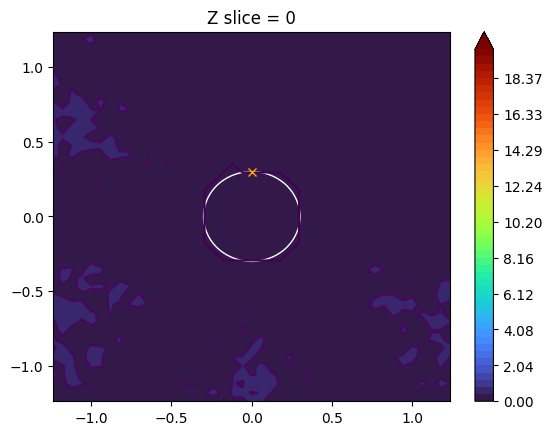

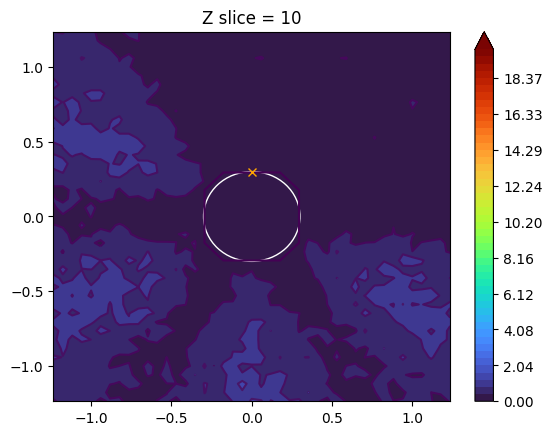

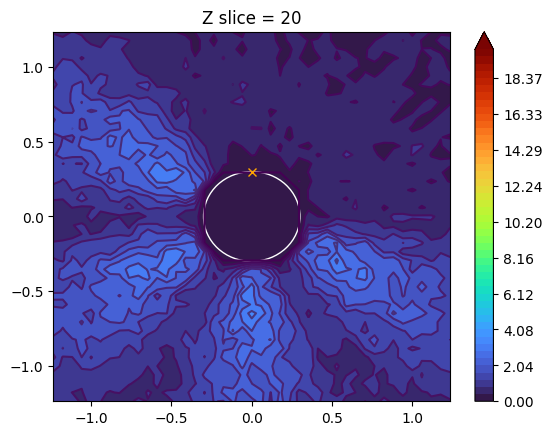

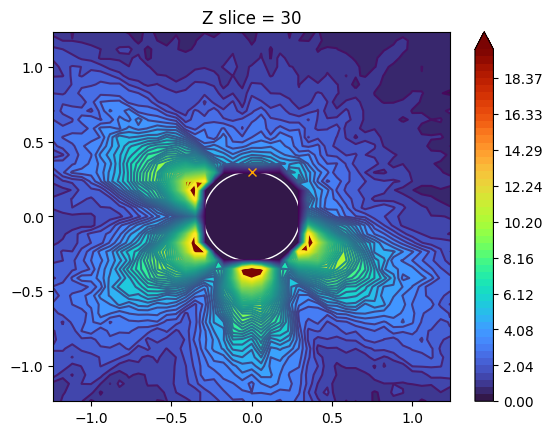

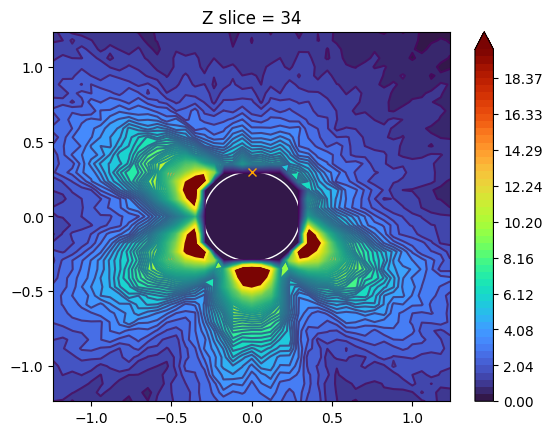

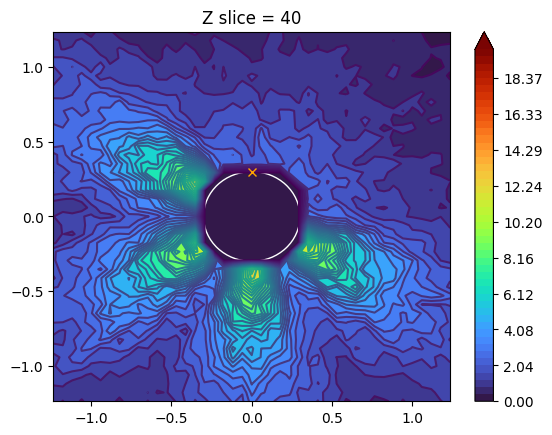

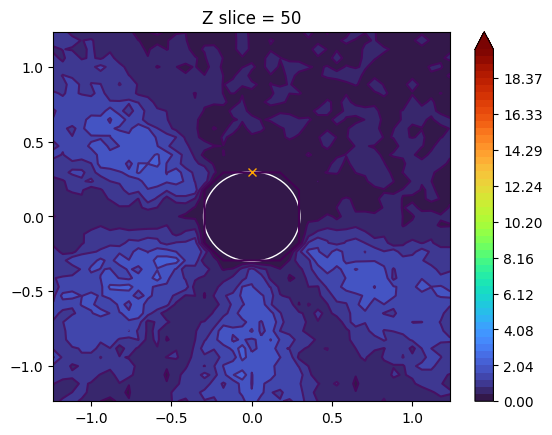

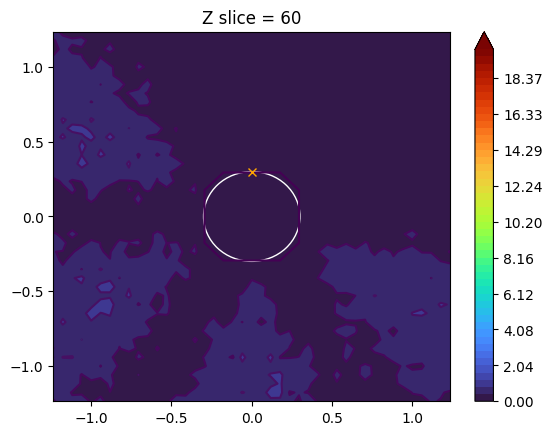

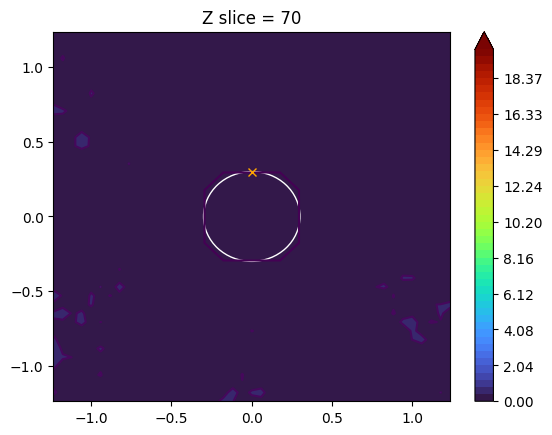

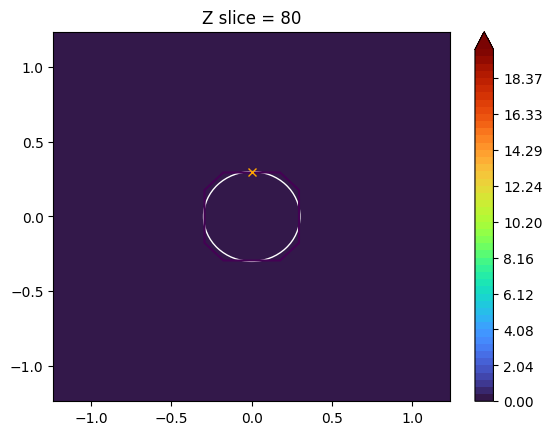

In [5]:
levels = np.linspace(0, 20, num=50)

for z in z_slices:
    Xz, Yz, energyz, __ = contour_energy(file, (bins, bins), dose_grid_half, z, 2, rngX, rngY, source_rad=source_rad[3] + 0.05, 
                                               scale=True, norm_energy=norm_energy, zero_source=True, std_dev=False)

    figz, axz = plt.subplots()
    
    contour = axz.contourf(Xz, Yz, energyz, locator=ticker.LinearLocator(), levels=levels, extend="max", cmap="turbo")
    axz.contour(Xz, Yz, energyz, levels=levels, extend="max")
    cbar = figz.colorbar(contour)
    
    circle = plt.Circle((0,0), radius=applicator_rad, edgecolor="white", fill=False)
    axz.add_patch(circle)
    axz.plot(norm_point[0], norm_point[1], color="orange", marker="x")
    axz.set_title("Z slice = " + str(z))